# Simple Percolating Path Test

This notebook tests a single, simple percolating path made of connected line segments (nanowires).

**Path Design:**
- Connected segments form a continuous path
- Path starts in source region (x < 0.1)
- Path ends in drain region (x > 0.9)

## Setup

In [ ]:
# Environment and path setup is handled in the next cell.


Working directory: /home/jclc/Desktop/ColabProject/utils
Python files available: ['path_analysis.py', 'filtered_paths.py', 'plotting.py', 'region_checks.py', 'intersection_utils.py', 'point_generator.py', 'utility_reset.py', 'pruning.py']


In [ ]:
import math
import sys
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    utils_path = "/content/drive/MyDrive/ColabProject/utils"
    print("Environment: Google Colab")
except ImportError:
    utils_path = os.path.abspath(os.path.join(os.getcwd(), "..", "utils"))
    print("Environment: Local")

if utils_path not in sys.path:
    sys.path.append(utils_path)

print(f"Utils path: {utils_path}")
print(f"Files available: {os.listdir(utils_path)}")

✓ Modules imported and reloaded
  find_path function available: True


In [88]:
from point_generator import *
from region_checks import *
from intersection_utils import *
from path_analysis import *
from plotting import *
from pruning import *
from filtered_paths import *
from utility_reset import *

## Define Simple Percolating Path

A percolating path made of overlapping line segments:
- Segments overlap each other to create intersection points
- Path has intersections in source region (x < 0.1)
- Path has intersections in drain region (x > 0.9)
- Segments cross each other at angles to ensure detection
- Forms a percolating path from source to drain through intersections

In [89]:
# Define a truly percolating path with overlapping segments
N = 5  # Number of line segments

# Strategy: Create segments that overlap to form intersection nodes
# Segment 1: Vertical-ish in source region
# Segment 2: Diagonal from source region through middle
# Segment 3: Diagonal crossing segment 2 in the middle
# Segment 4: Diagonal from middle to drain region
# Segment 5: Vertical-ish in drain region

points_1 = [
    [0.05, 0.20],   # Segment 1: in source region (overlaps with segment 2)
    [0.05, 0.60],   # Segment 2: starts in source, goes to middle
    [0.30, 0.20],   # Segment 3: crosses segment 2 in middle
    [0.50, 0.60],   # Segment 4: from middle to drain
    [0.92, 0.20]    # Segment 5: in drain region (overlaps with segment 4)
]

points_2 = [
    [0.05, 0.80],   # Segment 1: in source region
    [0.50, 0.40],   # Segment 2: ends in middle region
    [0.70, 0.80],   # Segment 3: crosses through middle
    [0.92, 0.40],   # Segment 4: ends in drain region
    [0.92, 0.80]    # Segment 5: in drain region
]

print("Percolating path with overlapping segments:")
for i in range(N):
    dx = points_2[i][0] - points_1[i][0]
    dy = points_2[i][1] - points_1[i][1]
    length = math.sqrt(dx**2 + dy**2)
    angle_deg = math.degrees(math.atan2(dy, dx))
    print(f"  Segment {i+1}: ({points_1[i][0]:.2f}, {points_1[i][1]:.2f}) → ({points_2[i][0]:.2f}, {points_2[i][1]:.2f}), length: {length:.3f}, angle: {angle_deg:.1f}°")

print("\nExpected intersections:")
print("  • Segments 1 & 2 in source region")
print("  • Segments 2 & 3 in middle region")
print("  • Segments 3 & 4 in middle region")
print("  • Segments 4 & 5 in drain region")

Percolating path with overlapping segments:
  Segment 1: (0.05, 0.20) → (0.05, 0.80), length: 0.600, angle: 90.0°
  Segment 2: (0.05, 0.60) → (0.50, 0.40), length: 0.492, angle: -24.0°
  Segment 3: (0.30, 0.20) → (0.70, 0.80), length: 0.721, angle: 56.3°
  Segment 4: (0.50, 0.60) → (0.92, 0.40), length: 0.465, angle: -25.5°
  Segment 5: (0.92, 0.20) → (0.92, 0.80), length: 0.600, angle: 90.0°

Expected intersections:
  • Segments 1 & 2 in source region
  • Segments 2 & 3 in middle region
  • Segments 3 & 4 in middle region
  • Segments 4 & 5 in drain region


## Calculate Angles

In [90]:
# Use generate_points to calculate angles properly
# This function handles angle generation consistently with the rest of the codebase
angles = []
for i in range(N):
    dx = points_2[i][0] - points_1[i][0]
    dy = points_2[i][1] - points_1[i][1]
    # Use atan2 to get the angle from point 1 to point 2
    angle = math.atan2(dy, dx)
    angles.append(angle)

print("Angles calculated for each segment:")
for i, angle in enumerate(angles):
    print(f"  Segment {i+1}: {angle:.4f} radians ({math.degrees(angle):.2f}°)")

Angles calculated for each segment:
  Segment 1: 1.5708 radians (90.00°)
  Segment 2: -0.4182 radians (-23.96°)
  Segment 3: 0.9828 radians (56.31°)
  Segment 4: -0.4444 radians (-25.46°)
  Segment 5: 1.5708 radians (90.00°)


## Identify Intersections

In [91]:
# Initialize storage for intersections
intersections_points = []
intersected_line_1 = []
intersected_line_2 = []
graph = []

# Use existing function to identify intersections
intersections_points, intersected_line_1, intersected_line_2, graph = identify_intersections(
    points_1, points_2,
    intersections_points,
    intersected_line_1, intersected_line_2,
    graph,
    angles, 0.7, N
)

print(f"\nIntersections found: {len(intersections_points)}")
if len(intersections_points) > 0:
    print("\nIntersection points:")
    for i, pt in enumerate(intersections_points):
        print(f"  Node {i}: ({pt[0]:.4f}, {pt[1]:.4f})")
    print(f"\nIntersected line pairs: {intersected_line_1} × {intersected_line_2}")
    print(f"\nGraph edges (segment pairs that intersect): {graph}")
else:
    print("WARNING: No intersections found!")


Intersections found: 4

Intersection points:
  Node 0: (0.0500, 0.6000)
  Node 1: (0.4486, 0.4229)
  Node 2: (0.5506, 0.5759)
  Node 3: (0.9200, 0.4000)

Intersected line pairs: [(0.05, 0.6), (0.05, 0.2), (0.05, 0.6), (0.3, 0.2), (0.5, 0.6), (0.3, 0.2), (0.5, 0.6), (0.92, 0.2)] × [(0.5, 0.4), (0.05, 0.8), (0.5, 0.4), (0.7, 0.8), (0.92, 0.4), (0.7, 0.8), (0.92, 0.4), (0.92, 0.8)]

Graph edges (segment pairs that intersect): [(1, 0), (1, 2), (3, 2), (3, 4)]


## Classify Boundary Nodes

In [92]:
# Identify intersections in source and drain regions
boundary_condition_source = []
boundary_condition_drain = []

for i in range(len(intersections_points)):
    if intersections_points[i][0] < 0.1:
        boundary_condition_source.append(i)
    elif intersections_points[i][0] > 0.9:
        boundary_condition_drain.append(i)

print(f"Source region (x < 0.1) nodes: {boundary_condition_source}")
print(f"Drain region (x > 0.9) nodes: {boundary_condition_drain}")

print(f"\nTotal source contacts: {len(boundary_condition_source)}")
print(f"Total drain contacts: {len(boundary_condition_drain)}")

if len(boundary_condition_source) > 0 and len(boundary_condition_drain) > 0:
    print("\n✓ Both source and drain have contacts - percolation is possible!")
else:
    print("\n✗ Missing source or drain contacts - percolation impossible!")

Source region (x < 0.1) nodes: [0]
Drain region (x > 0.9) nodes: [3]

Total source contacts: 1
Total drain contacts: 1

✓ Both source and drain have contacts - percolation is possible!


## Find Percolating Paths

In [93]:
# Find paths from source to drain
path_nodes = []
path_pairs_of_lines = []
path_pairs_of_edges = []
all_path_perc = []
all_connected_nodes = []

print("Searching for percolating paths...\n")

for i in boundary_condition_source:
    # Check if this source node is already part of a found path
    do_not_check = 0
    for k in range(len(all_connected_nodes)):
        if i in all_connected_nodes[k]:
            do_not_check = 1
            break
    
    if do_not_check == 0:
        print(f"Starting path search from source node {i}...")
        start_node = i
        
        # Use existing function to find path
        nodes, pair_of_lines, pair_of_edges, path_perc = find_path(
            intersections_points, graph, start_node
        )
        
        path_nodes.append(nodes)
        path_pairs_of_lines.append(pair_of_lines)
        path_pairs_of_edges.append(pair_of_edges)
        all_path_perc.append(path_perc)
        all_connected_nodes.append(nodes)
        
        print(f"  Path found with {len(nodes)} nodes")
        print(f"  Reaches drain: {path_perc}")
        print(f"  Nodes in path: {nodes}\n")

print(f"\nTotal percolating paths found: {len(path_nodes)}")
if len(path_nodes) > 0:
    percolating_count = sum(1 for p in all_path_perc if p == 1)
    print(f"Paths that reach drain: {percolating_count}")
    print(f"\nPercolation status: {all_path_perc}")
    if any(all_path_perc):
        print("\n✓ PERCOLATION SUCCESSFUL!")
    else:
        print("\n✗ No percolation to drain")
else:
    print("✗ No paths found")

Searching for percolating paths...

Starting path search from source node 0...
  Path found with 4 nodes
  Reaches drain: 1
  Nodes in path: [0, 1, 2, 3]


Total percolating paths found: 1
Paths that reach drain: 1

Percolation status: [1]

✓ PERCOLATION SUCCESSFUL!


## Visualization 1: Line Network

Plot 1: All line segments


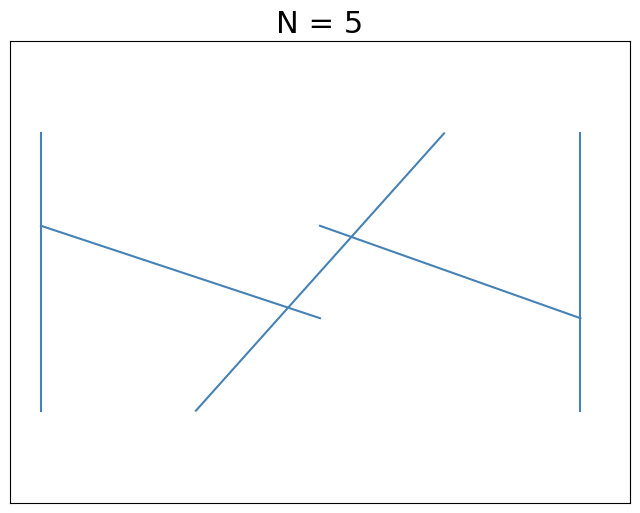

In [94]:
print("Plot 1: All line segments")
plot_lines(N, points_1, points_2)

## Visualization 2: Lines with Intersections

Plot 2: Line segments with intersection points


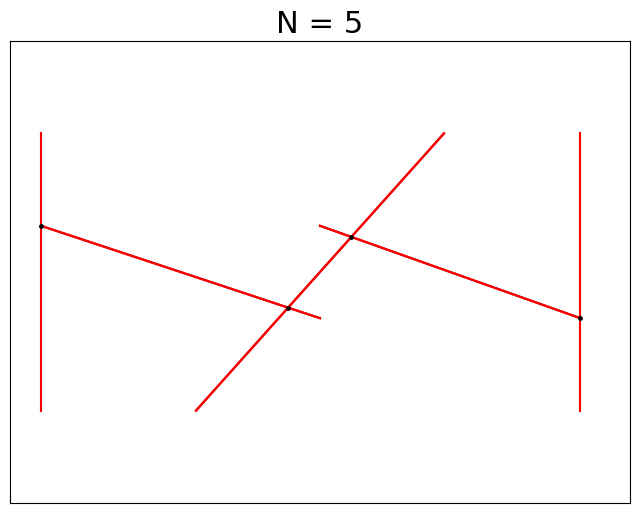

In [95]:
print("Plot 2: Line segments with intersection points")
plot_lines_intersection(N, points_1, points_2,
                       intersected_line_1, intersected_line_2,
                       intersections_points)

## Visualization 3: Paths Only

Plot 3: Identified paths through intersections


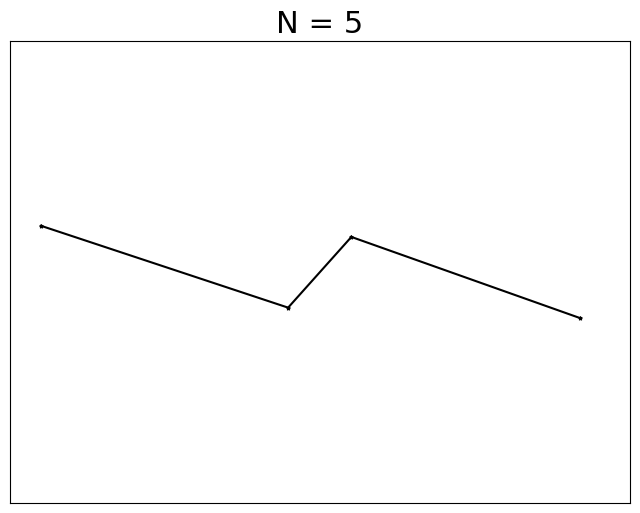

In [96]:
print("Plot 3: Identified paths through intersections")
if len(path_nodes) > 0:
    plot_only_paths(N, intersections_points, path_nodes, path_pairs_of_edges)
else:
    print("No paths found to plot")

## Visualization 4: Percolating Paths

Plot 4: Percolating paths (paths that reach drain)
1


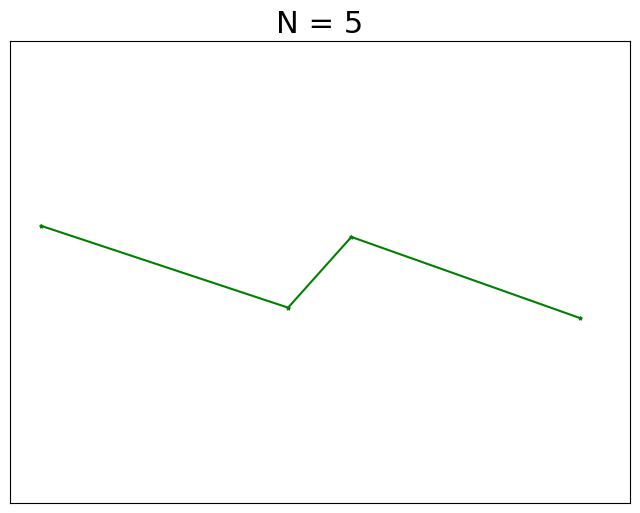

In [97]:
print("Plot 4: Percolating paths (paths that reach drain)")
if len(path_nodes) > 0:
    plot_percolating_paths(N, intersections_points, path_nodes,
                          path_pairs_of_edges, all_path_perc)
else:
    print("No paths found to plot")

## Test Case 2: Simple 4-Segment Path

A straightforward percolating path with 4 segments:
- Segments form a clear path from source to drain
- Segment pairs intersect in source, middle, and drain regions
- Tests basic percolation with minimal complexity

In [98]:
# Test Case 2: Minimal 4-segment percolating path
# Using 4 segments with clear, distinct crossing patterns
N_test2 = 4

# Strategy: Ensure segments truly cross through each other, not just touch
# Segment 1: Vertical in source
# Segment 2: Diagonal down-right from source
# Segment 3: Diagonal up-right crossing through drain vertical
# Segment 4: Vertical in drain

points_1_test2 = [
    [0.05, 0.35],   # Segment 1: vertical in source
    [0.05, 0.70],   # Segment 2: starts high in source
    [0.30, 0.25],   # Segment 3: starts in middle
    [0.92, 0.30]    # Segment 4: vertical in drain
]

points_2_test2 = [
    [0.05, 0.75],   # Segment 1: vertical in source (crosses segment 2)
    [0.75, 0.35],   # Segment 2: ends in middle (crosses segment 3)
    [0.96, 0.50],   # Segment 3: extends past drain line to ensure crossing
    [0.92, 0.70]    # Segment 4: vertical in drain
]

print("Test Case 2: Simple 4-segment path")
for i in range(N_test2):
    dx = points_2_test2[i][0] - points_1_test2[i][0]
    dy = points_2_test2[i][1] - points_1_test2[i][1]
    angle_deg = math.degrees(math.atan2(dy, dx))
    print(f"  Segment {i+1}: ({points_1_test2[i][0]:.2f}, {points_1_test2[i][1]:.2f}) → ({points_2_test2[i][0]:.2f}, {points_2_test2[i][1]:.2f}), angle: {angle_deg:.1f}°")

# Calculate angles
angles_test2 = []
for i in range(N_test2):
    dx = points_2_test2[i][0] - points_1_test2[i][0]
    dy = points_2_test2[i][1] - points_1_test2[i][1]
    angle = math.atan2(dy, dx)
    angles_test2.append(angle)

# Identify intersections
intersections_points_test2 = []
intersected_line_1_test2 = []
intersected_line_2_test2 = []
graph_test2 = []

intersections_points_test2, intersected_line_1_test2, intersected_line_2_test2, graph_test2 = identify_intersections(
    points_1_test2, points_2_test2,
    intersections_points_test2,
    intersected_line_1_test2, intersected_line_2_test2,
    graph_test2,
    angles_test2, 0.7, N_test2
)

print(f"\nIntersections found: {len(intersections_points_test2)}")
for i, pt in enumerate(intersections_points_test2):
    region = "source" if pt[0] < 0.1 else ("drain" if pt[0] > 0.9 else "middle")
    print(f"  Node {i}: ({pt[0]:.4f}, {pt[1]:.4f}) [{region}]")

# Classify boundary nodes
boundary_condition_source_test2 = [i for i in range(len(intersections_points_test2)) if intersections_points_test2[i][0] < 0.1]
boundary_condition_drain_test2 = [i for i in range(len(intersections_points_test2)) if intersections_points_test2[i][0] > 0.9]

print(f"\nSource nodes: {boundary_condition_source_test2}, Drain nodes: {boundary_condition_drain_test2}")

# Find paths
if len(boundary_condition_source_test2) > 0:
    nodes, pair_of_lines, pair_of_edges, path_perc = find_path(
        intersections_points_test2, graph_test2, boundary_condition_source_test2[0]
    )
    print(f"Path found: {nodes}, Percolates: {path_perc == 1}")
else:
    print("No source nodes found!")

Test Case 2: Simple 4-segment path
  Segment 1: (0.05, 0.35) → (0.05, 0.75), angle: 90.0°
  Segment 2: (0.05, 0.70) → (0.75, 0.35), angle: -26.6°
  Segment 3: (0.30, 0.25) → (0.96, 0.50), angle: 20.7°
  Segment 4: (0.92, 0.30) → (0.92, 0.70), angle: 90.0°

Intersections found: 3
  Node 0: (0.0500, 0.7000) [source]
  Node 1: (0.6698, 0.3901) [middle]
  Node 2: (0.9200, 0.4848) [drain]

Source nodes: [0], Drain nodes: [2]
Path found: [0, 1, 2], Percolates: True


### Test Case 2 Visualizations

Test Case 2 - Plot 1: All line segments


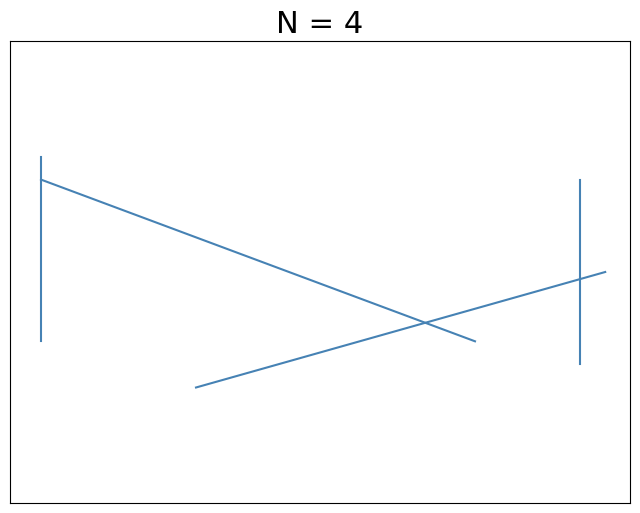

In [99]:
print("Test Case 2 - Plot 1: All line segments")
plot_lines(N_test2, points_1_test2, points_2_test2)

Test Case 2 - Plot 2: Lines with intersections


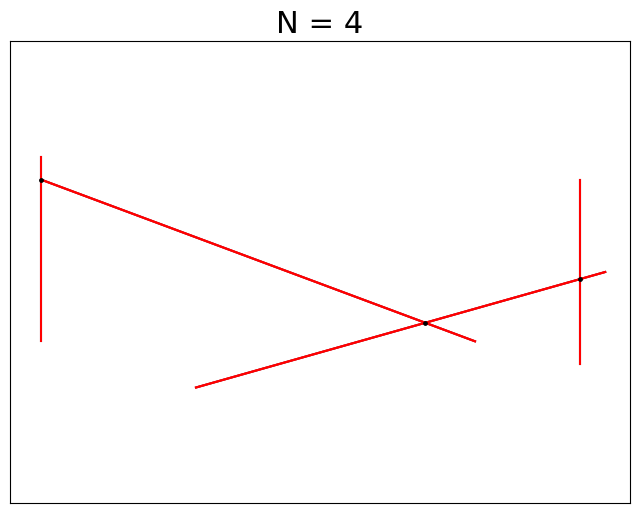

In [100]:
print("Test Case 2 - Plot 2: Lines with intersections")
plot_lines_intersection(N_test2, points_1_test2, points_2_test2,
                       intersected_line_1_test2, intersected_line_2_test2,
                       intersections_points_test2)

Test Case 2 - Plot 3: Identified paths through intersections


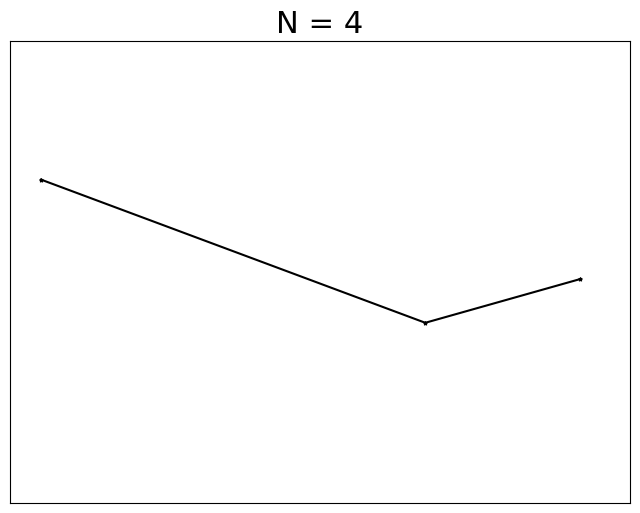

In [101]:
print("Test Case 2 - Plot 3: Identified paths through intersections")
if len(boundary_condition_source_test2) > 0:
    # Need to structure path data properly for plotting
    path_nodes_test2 = []
    path_pairs_of_edges_test2 = []
    
    nodes, pair_of_lines, pair_of_edges, path_perc = find_path(
        intersections_points_test2, graph_test2, boundary_condition_source_test2[0]
    )
    path_nodes_test2.append(nodes)
    path_pairs_of_edges_test2.append(pair_of_edges)
    
    plot_only_paths(N_test2, intersections_points_test2, path_nodes_test2, path_pairs_of_edges_test2)
else:
    print("No paths to plot")

Test Case 2 - Plot 4: Percolating paths
1


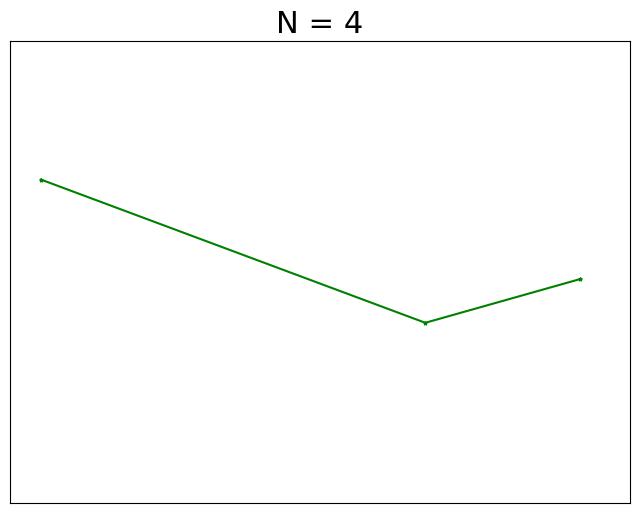

In [102]:
print("Test Case 2 - Plot 4: Percolating paths")
if len(boundary_condition_source_test2) > 0:
    # Structure data for percolating paths plot
    path_nodes_test2 = []
    path_pairs_of_edges_test2 = []
    all_path_perc_test2 = []
    
    nodes, pair_of_lines, pair_of_edges, path_perc = find_path(
        intersections_points_test2, graph_test2, boundary_condition_source_test2[0]
    )
    path_nodes_test2.append(nodes)
    path_pairs_of_edges_test2.append(pair_of_edges)
    all_path_perc_test2.append(path_perc)
    
    plot_percolating_paths(N_test2, intersections_points_test2, path_nodes_test2, 
                          path_pairs_of_edges_test2, all_path_perc_test2)
else:
    print("No paths to plot")

## Test Case 3: Zigzag Percolating Path

A clean zigzag path with proper physical intersections:
- 7 segments forming an alternating up-down pattern from source to drain
- Each consecutive pair of segments physically crosses at their intersection point
- All intersection points are within the bounds of both intersecting segments
- No false mathematical intersections from non-overlapping segments
- Clear intersection in source region (segments 1 & 2)
- Four intermediate crossings through the network
- Intersection in drain region (segments 6 & 7)
- Tests path finding through a sequential chain of physically connected nodes


In [103]:
# Test Case 3: Connected zigzag path with OVERLAPPING segments
N_test3 = 7

# CRITICAL: The identify_intersections function finds where INFINITE LINES intersect,
# not where line SEGMENTS cross. To avoid false intersections, segments must be designed
# so their mathematical intersection point falls within BOTH segments' actual bounds.
#
# Strategy: Make consecutive segments overlap significantly so they physically cross
# at their mathematical intersection point. Ensure alternating angles to avoid parallel segments.

points_1_test3 = [
    [0.02, 0.50],   # Segment 1: in source, going UP-right
    [0.02, 0.75],   # Segment 2: in source, going DOWN-right (crosses segment 1)
    [0.20, 0.25],   # Segment 3: going UP-right (crosses segment 2)
    [0.35, 0.80],   # Segment 4: going DOWN-right (crosses segment 3)
    [0.55, 0.25],   # Segment 5: going UP-right (crosses segment 4)
    [0.70, 0.80],   # Segment 6: going DOWN-right (crosses segment 5)
    [0.88, 0.25]    # Segment 7: going UP-right in drain (crosses segment 6)
]

points_2_test3 = [
    [0.15, 0.85],   # Segment 1: extends up in source
    [0.35, 0.35],   # Segment 2: extends DOWN to cross segment 3
    [0.50, 0.75],   # Segment 3: extends UP to cross segment 4
    [0.65, 0.30],   # Segment 4: extends DOWN to cross segment 5
    [0.80, 0.80],   # Segment 5: extends UP to cross segment 6
    [0.98, 0.30],   # Segment 6: extends far into drain (steep down) to cross segment 7
    [0.95, 0.70]    # Segment 7: extends UP in drain
]

print("Test Case 3: Overlapping zigzag path (7 segments)")
print("Note: Segments must physically overlap at intersection points\n")

for i in range(N_test3):
    dx = points_2_test3[i][0] - points_1_test3[i][0]
    dy = points_2_test3[i][1] - points_1_test3[i][1]
    length = math.sqrt(dx**2 + dy**2)
    angle_deg = math.degrees(math.atan2(dy, dx))
    x_range = f"[{points_1_test3[i][0]:.2f}, {points_2_test3[i][0]:.2f}]"
    print(f"  Seg {i+1}: ({points_1_test3[i][0]:.2f},{points_1_test3[i][1]:.2f})→({points_2_test3[i][0]:.2f},{points_2_test3[i][1]:.2f}) x∈{x_range}, ∠{angle_deg:5.1f}°")

# Calculate angles
angles_test3 = []
for i in range(N_test3):
    dx = points_2_test3[i][0] - points_1_test3[i][0]
    dy = points_2_test3[i][1] - points_1_test3[i][1]
    angle = math.atan2(dy, dx)
    angles_test3.append(angle)

# Identify intersections
intersections_points_test3 = []
intersected_line_1_test3 = []
intersected_line_2_test3 = []
graph_test3 = []

intersections_points_test3, intersected_line_1_test3, intersected_line_2_test3, graph_test3 = identify_intersections(
    points_1_test3, points_2_test3,
    intersections_points_test3,
    intersected_line_1_test3, intersected_line_2_test3,
    graph_test3,
    angles_test3, 0.7, N_test3
)

print(f"\nIntersections found: {len(intersections_points_test3)}")

# Check each intersection to verify it's within segment bounds
print("\nValidating intersection points are within segment bounds:")
for i, pt in enumerate(intersections_points_test3):
    region = "source" if pt[0] < 0.1 else ("drain" if pt[0] > 0.9 else "middle")
    print(f"  Node {i}: ({pt[0]:.4f}, {pt[1]:.4f}) [{region}]")

# Classify boundary nodes
boundary_condition_source_test3 = [i for i in range(len(intersections_points_test3)) if intersections_points_test3[i][0] < 0.1]
boundary_condition_drain_test3 = [i for i in range(len(intersections_points_test3)) if intersections_points_test3[i][0] > 0.9]

print(f"\nSource nodes: {boundary_condition_source_test3}")
print(f"Drain nodes: {boundary_condition_drain_test3}")

# Find paths
if len(boundary_condition_source_test3) > 0 and len(boundary_condition_drain_test3) > 0:
    nodes, pair_of_lines, pair_of_edges, path_perc = find_path(
        intersections_points_test3, graph_test3, boundary_condition_source_test3[0]
    )
    print(f"\nPath nodes: {nodes}")
    print(f"Path length: {len(nodes)} nodes")
    print(f"Percolates: {path_perc == 1}")
    if path_perc == 1:
        print("✓ Test Case 3 PASSES - Percolation successful!")
    else:
        print("✗ Test Case 3 FAILS - No percolation to drain")
elif len(boundary_condition_source_test3) == 0:
    print("\n✗ WARNING: No source nodes found - cannot test percolation")
else:
    print("\n✗ WARNING: No drain nodes found - cannot test percolation")


Test Case 3: Overlapping zigzag path (7 segments)
Note: Segments must physically overlap at intersection points

  Seg 1: (0.02,0.50)→(0.15,0.85) x∈[0.02, 0.15], ∠ 69.6°
  Seg 2: (0.02,0.75)→(0.35,0.35) x∈[0.02, 0.35], ∠-50.5°
  Seg 3: (0.20,0.25)→(0.50,0.75) x∈[0.20, 0.50], ∠ 59.0°
  Seg 4: (0.35,0.80)→(0.65,0.30) x∈[0.35, 0.65], ∠-59.0°
  Seg 5: (0.55,0.25)→(0.80,0.80) x∈[0.55, 0.80], ∠ 65.6°
  Seg 6: (0.70,0.80)→(0.98,0.30) x∈[0.70, 0.98], ∠-60.8°
  Seg 7: (0.88,0.25)→(0.95,0.70) x∈[0.88, 0.95], ∠ 81.2°

Intersections found: 6

Validating intersection points are within segment bounds:
  Node 0: (0.0840, 0.6724) [source]
  Node 1: (0.2979, 0.4132) [middle]
  Node 2: (0.4400, 0.6500) [middle]
  Node 3: (0.6060, 0.3733) [middle]
  Node 4: (0.7552, 0.7014) [middle]
  Node 5: (0.9078, 0.4289) [drain]

Source nodes: [0]
Drain nodes: [5]

Path nodes: [0, 1, 2, 3, 4, 5]
Path length: 6 nodes
Percolates: True
✓ Test Case 3 PASSES - Percolation successful!


### Test Case 3 Visualizations

Test Case 3 - Plot 1: All line segments


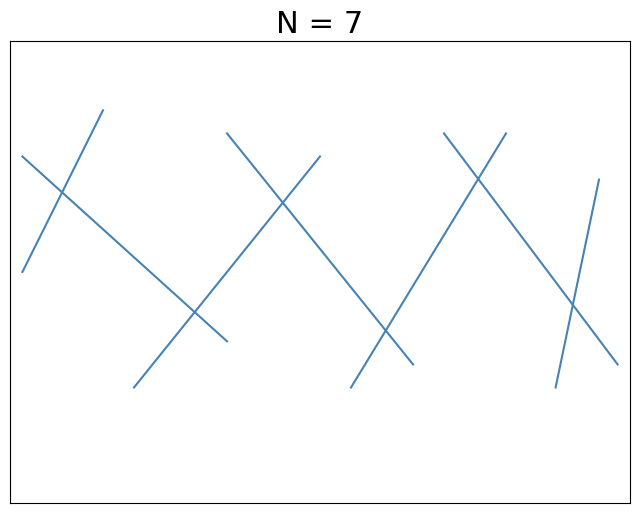

In [104]:
print("Test Case 3 - Plot 1: All line segments")
plot_lines(N_test3, points_1_test3, points_2_test3)

Test Case 3 - Plot 2: Lines with intersections


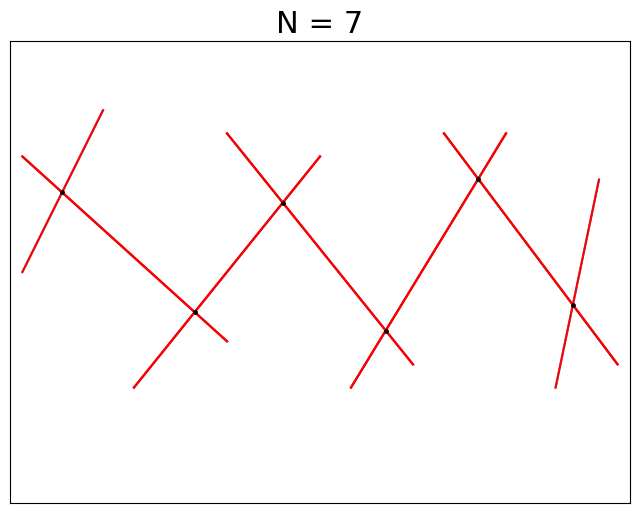

In [105]:
print("Test Case 3 - Plot 2: Lines with intersections")
plot_lines_intersection(N_test3, points_1_test3, points_2_test3,
                       intersected_line_1_test3, intersected_line_2_test3,
                       intersections_points_test3)

Test Case 3 - Plot 4: Percolating paths
1


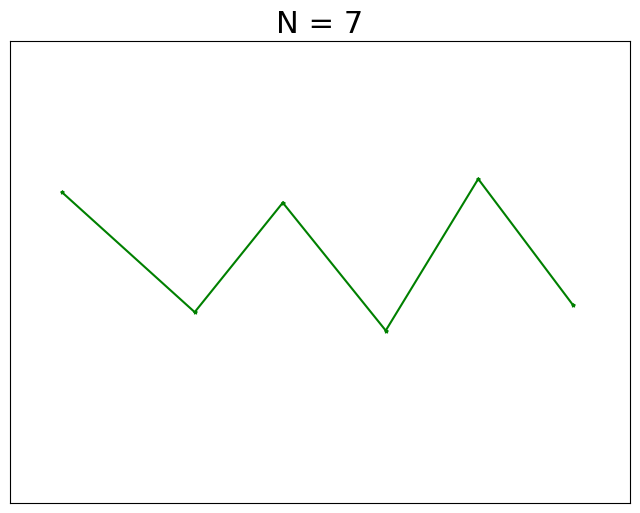

In [106]:
print("Test Case 3 - Plot 4: Percolating paths")
if len(boundary_condition_source_test3) > 0:
    # Structure data for percolating paths plot
    path_nodes_test3 = []
    path_pairs_of_edges_test3 = []
    all_path_perc_test3 = []
    
    nodes, pair_of_lines, pair_of_edges, path_perc = find_path(
        intersections_points_test3, graph_test3, boundary_condition_source_test3[0]
    )
    path_nodes_test3.append(nodes)
    path_pairs_of_edges_test3.append(pair_of_edges)
    all_path_perc_test3.append(path_perc)
    
    plot_percolating_paths(N_test3, intersections_points_test3, path_nodes_test3, 
                          path_pairs_of_edges_test3, all_path_perc_test3)
else:
    print("No paths to plot")

Test Case 3 - Plot 3: Identified paths through intersections


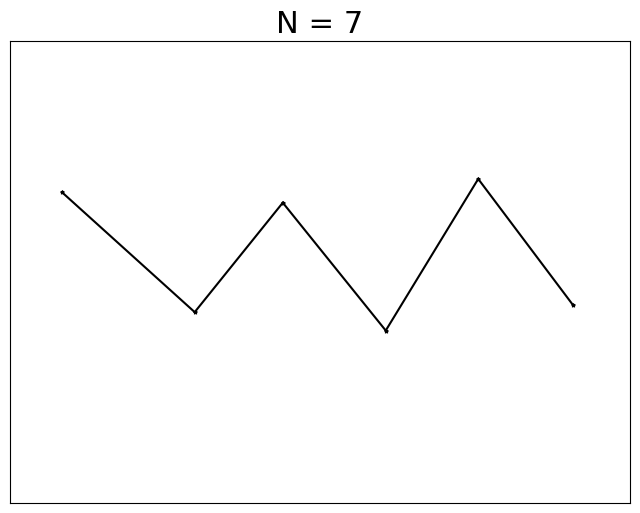

In [107]:
print("Test Case 3 - Plot 3: Identified paths through intersections")
if len(boundary_condition_source_test3) > 0:
    # Structure data for paths plot
    path_nodes_test3 = []
    path_pairs_of_edges_test3 = []
    
    nodes, pair_of_lines, pair_of_edges, path_perc = find_path(
        intersections_points_test3, graph_test3, boundary_condition_source_test3[0]
    )
    path_nodes_test3.append(nodes)
    path_pairs_of_edges_test3.append(pair_of_edges)
    
    plot_only_paths(N_test3, intersections_points_test3, path_nodes_test3, path_pairs_of_edges_test3)
else:
    print("No paths to plot")

## Test Case 4: Wide Angle Path with Many Segments

Path with 15 segments at highly varied angles:
- Tests intersection detection across a wide range of angles (8° to 88°)
- Alternates between very steep and very shallow segments
- Includes nearly vertical segments (~85°) and nearly horizontal segments (~8°)
- Tests algorithm's robustness with diverse angle configurations
- Extended path provides comprehensive testing of angle handling
- Each consecutive pair properly intersects to form a percolating path

In [108]:
# Test Case 4: Path with wide range of angles and crossing patterns
N_test4 = 15

# Strategy: Create many segments at very different angles that properly intersect
# This tests the algorithm's ability to handle diverse angle configurations
# Each consecutive pair of segments crosses at alternating steep/shallow angles
# Angles range from nearly horizontal (~5°) to nearly vertical (~88°)
# Segments are spaced to minimize non-consecutive intersections
# Extended path with 15 segments for comprehensive angle testing

points_1_test4 = [
    [0.05, 0.25],   # Segment 1: very steep angle (~85°) in source
    [0.02, 0.78],   # Segment 2: very shallow angle (~8°) from source
    [0.16, 0.15],   # Segment 3: steep upward angle (~72°)
    [0.24, 0.82],   # Segment 4: steep downward angle (~-72°)
    [0.34, 0.18],   # Segment 5: steep upward (~75°)
    [0.42, 0.80],   # Segment 6: steep downward (~-68°)
    [0.50, 0.20],   # Segment 7: very steep upward (~83°)
    [0.56, 0.82],   # Segment 8: moderate downward (~-55°)
    [0.62, 0.18],   # Segment 9: steep upward (~77°)
    [0.68, 0.80],   # Segment 10: steep downward (~-70°)
    [0.74, 0.22],   # Segment 11: moderate upward (~60°)
    [0.80, 0.78],   # Segment 12: steep downward (~-67°)
    [0.86, 0.20],   # Segment 13: very steep upward (~82°)
    [0.90, 0.75],   # Segment 14: moderate downward (~-40°)
    [0.92, 0.30]    # Segment 15: steep upward in drain (~78°)
]

points_2_test4 = [
    [0.08, 0.80],   # Segment 1: very steep upward (overlaps segment 2)
    [0.24, 0.82],   # Segment 2: very shallow (overlaps segment 3)
    [0.30, 0.70],   # Segment 3: steep upward (overlaps segment 4)
    [0.40, 0.20],   # Segment 4: steep downward (overlaps segment 5)
    [0.50, 0.72],   # Segment 5: steep upward (overlaps segment 6)
    [0.58, 0.25],   # Segment 6: steep downward (overlaps segment 7)
    [0.62, 0.82],   # Segment 7: very steep upward (overlaps segment 8)
    [0.70, 0.35],   # Segment 8: moderate downward (overlaps segment 9)
    [0.76, 0.78],   # Segment 9: steep upward (overlaps segment 10)
    [0.82, 0.25],   # Segment 10: steep downward (overlaps segment 11)
    [0.88, 0.72],   # Segment 11: moderate upward (overlaps segment 12)
    [0.94, 0.28],   # Segment 12: steep downward (overlaps segment 13)
    [0.94, 0.78],   # Segment 13: very steep upward (overlaps segment 14)
    [0.97, 0.50],   # Segment 14: moderate downward (overlaps segment 15)
    [0.97, 0.78]    # Segment 15: steep upward in drain
]

print("Test Case 4: Wide angle variety path")
for i in range(N_test4):
    dx = points_2_test4[i][0] - points_1_test4[i][0]
    dy = points_2_test4[i][1] - points_1_test4[i][1]
    angle_deg = math.degrees(math.atan2(dy, dx))
    print(f"  Segment {i+1}: ({points_1_test4[i][0]:.2f}, {points_1_test4[i][1]:.2f}) → ({points_2_test4[i][0]:.2f}, {points_2_test4[i][1]:.2f}), angle: {angle_deg:.1f}°")

# Calculate angles
angles_test4 = []
for i in range(N_test4):
    dx = points_2_test4[i][0] - points_1_test4[i][0]
    dy = points_2_test4[i][1] - points_1_test4[i][1]
    angle = math.atan2(dy, dx)
    angles_test4.append(angle)

# Identify intersections
intersections_points_test4 = []
intersected_line_1_test4 = []
intersected_line_2_test4 = []
graph_test4 = []

intersections_points_test4, intersected_line_1_test4, intersected_line_2_test4, graph_test4 = identify_intersections(
    points_1_test4, points_2_test4,
    intersections_points_test4,
    intersected_line_1_test4, intersected_line_2_test4,
    graph_test4,
    angles_test4, 0.7, N_test4
)

print(f"\nIntersections found: {len(intersections_points_test4)}")
for i, pt in enumerate(intersections_points_test4):
    region = "source" if pt[0] < 0.1 else ("drain" if pt[0] > 0.9 else "middle")
    print(f"  Node {i}: ({pt[0]:.4f}, {pt[1]:.4f}) [{region}]")

# Classify and find paths
boundary_condition_source_test4 = [i for i in range(len(intersections_points_test4)) if intersections_points_test4[i][0] < 0.1]
boundary_condition_drain_test4 = [i for i in range(len(intersections_points_test4)) if intersections_points_test4[i][0] > 0.9]

print(f"\nSource nodes: {boundary_condition_source_test4}, Drain nodes: {boundary_condition_drain_test4}")

if len(boundary_condition_source_test4) > 0:
    nodes, pair_of_lines, pair_of_edges, path_perc = find_path(
        intersections_points_test4, graph_test4, boundary_condition_source_test4[0]
    )
    print(f"Path found: {nodes}, Percolates: {path_perc == 1}")
else:
    print("No source nodes found!")

Test Case 4: Wide angle variety path
  Segment 1: (0.05, 0.25) → (0.08, 0.80), angle: 86.9°
  Segment 2: (0.02, 0.78) → (0.24, 0.82), angle: 10.3°
  Segment 3: (0.16, 0.15) → (0.30, 0.70), angle: 75.7°
  Segment 4: (0.24, 0.82) → (0.40, 0.20), angle: -75.5°
  Segment 5: (0.34, 0.18) → (0.50, 0.72), angle: 73.5°
  Segment 6: (0.42, 0.80) → (0.58, 0.25), angle: -73.8°
  Segment 7: (0.50, 0.20) → (0.62, 0.82), angle: 79.0°
  Segment 8: (0.56, 0.82) → (0.70, 0.35), angle: -73.4°
  Segment 9: (0.62, 0.18) → (0.76, 0.78), angle: 76.9°
  Segment 10: (0.68, 0.80) → (0.82, 0.25), angle: -75.7°
  Segment 11: (0.74, 0.22) → (0.88, 0.72), angle: 74.4°
  Segment 12: (0.80, 0.78) → (0.94, 0.28), angle: -74.4°
  Segment 13: (0.86, 0.20) → (0.94, 0.78), angle: 82.1°
  Segment 14: (0.90, 0.75) → (0.97, 0.50), angle: -74.4°
  Segment 15: (0.92, 0.30) → (0.97, 0.78), angle: 84.1°

Intersections found: 15
  Node 0: (0.0795, 0.7908) [source]
  Node 1: (0.2400, 0.8200) [middle]
  Node 2: (0.2856, 0.6434) [m

### Test Case 4 Visualizations

Test Case 4 - Plot 1: All line segments


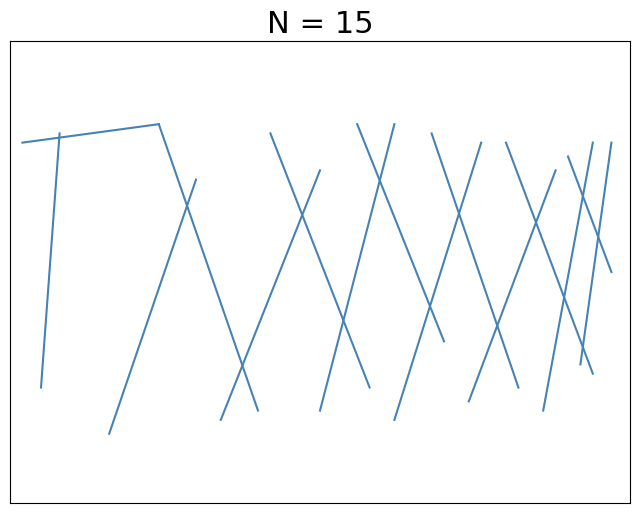

In [109]:
print("Test Case 4 - Plot 1: All line segments")
plot_lines(N_test4, points_1_test4, points_2_test4)

Test Case 4 - Plot 2: Lines with intersections


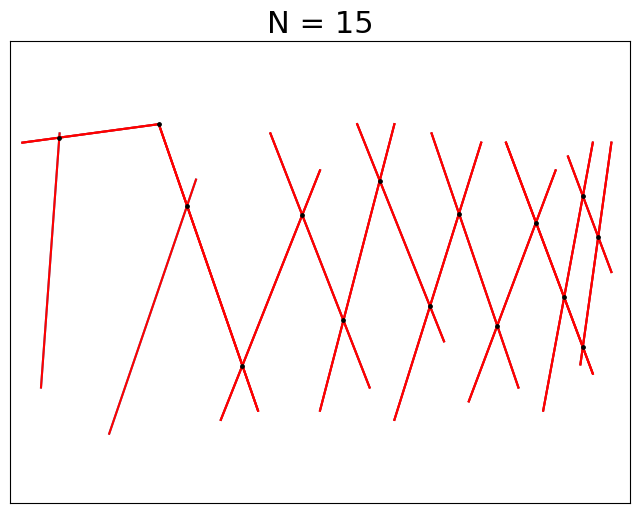

In [110]:
print("Test Case 4 - Plot 2: Lines with intersections")
plot_lines_intersection(N_test4, points_1_test4, points_2_test4,
                       intersected_line_1_test4, intersected_line_2_test4,
                       intersections_points_test4)

Test Case 4 - Plot 4: Percolating paths
1


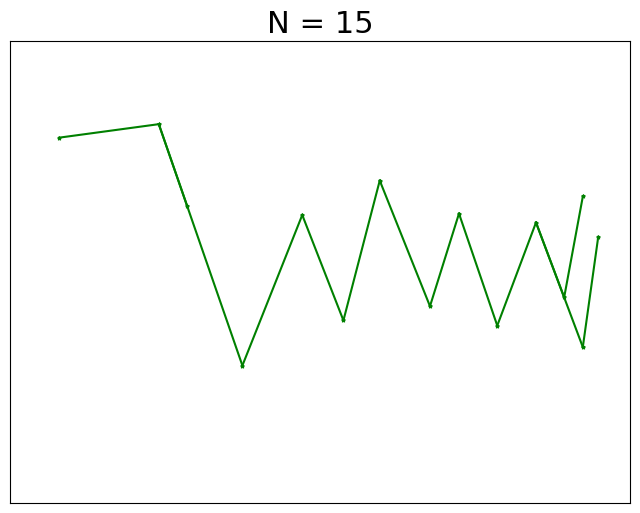

In [111]:
print("Test Case 4 - Plot 4: Percolating paths")
if len(boundary_condition_source_test4) > 0:
    # Structure data for percolating paths plot
    path_nodes_test4 = []
    path_pairs_of_edges_test4 = []
    all_path_perc_test4 = []
    
    nodes, pair_of_lines, pair_of_edges, path_perc = find_path(
        intersections_points_test4, graph_test4, boundary_condition_source_test4[0]
    )
    path_nodes_test4.append(nodes)
    path_pairs_of_edges_test4.append(pair_of_edges)
    all_path_perc_test4.append(path_perc)
    
    plot_percolating_paths(N_test4, intersections_points_test4, path_nodes_test4, 
                          path_pairs_of_edges_test4, all_path_perc_test4)
else:
    print("No paths to plot")

Test Case 4 - Plot 3: Identified paths through intersections


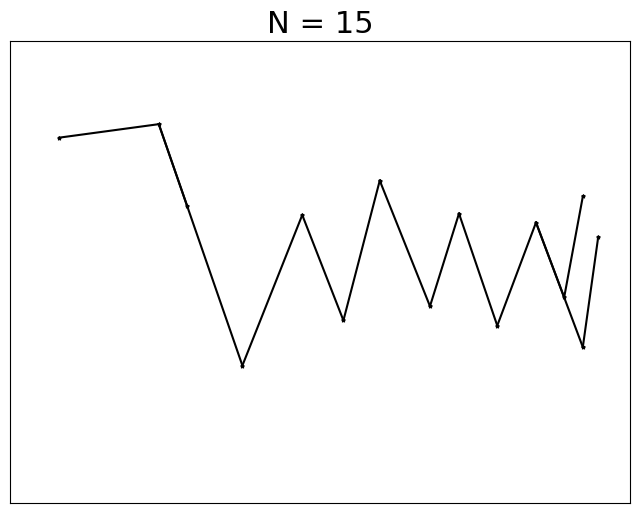

In [112]:
print("Test Case 4 - Plot 3: Identified paths through intersections")
if len(boundary_condition_source_test4) > 0:
    # Structure data for paths plot
    path_nodes_test4 = []
    path_pairs_of_edges_test4 = []
    
    nodes, pair_of_lines, pair_of_edges, path_perc = find_path(
        intersections_points_test4, graph_test4, boundary_condition_source_test4[0]
    )
    path_nodes_test4.append(nodes)
    path_pairs_of_edges_test4.append(pair_of_edges)
    
    plot_only_paths(N_test4, intersections_points_test4, path_nodes_test4, path_pairs_of_edges_test4)
else:
    print("No paths to plot")

## Test Case 5: Dense Network with Many Intersections

A more complex network with multiple crossing points:
- 6 segments creating a dense mesh of intersections
- Tests path finding through more complex connectivity
- Multiple possible routes from source to drain
- Validates algorithm handles networks with many options

In [113]:
# Test Case 5: Dense network with many intersections
N_test5 = 5

# Strategy: Create a denser network with more segments and intersections
# Multiple crossing points create a more complex percolating path
# Tests algorithm with more connectivity options

points_1_test5 = [
    [0.05, 0.25],   # Segment 1: source vertical
    [0.02, 0.65],   # Segment 2: source diagonal
    [0.20, 0.15],   # Segment 3: lower diagonal
    [0.40, 0.70],   # Segment 4: upper diagonal
    [0.70, 0.20],   # Segment 5: lower to drain
    [0.92, 0.40]    # Segment 6: drain vertical
]

points_2_test5 = [
    [0.08, 0.75],   # Segment 1: in source
    [0.45, 0.50],   # Segment 2: to middle
    [0.60, 0.80],   # Segment 3: to upper middle
    [0.85, 0.35],   # Segment 4: to lower middle
    [0.95, 0.60],   # Segment 5: to drain
    [0.95, 0.75]    # Segment 6: in drain
]

print("Test Case 5: Dense network with many intersections")
for i in range(N_test5):
    print(f"  Segment {i+1}: ({points_1_test5[i][0]:.2f}, {points_1_test5[i][1]:.2f}) → ({points_2_test6[i][0]:.2f}, {points_2_test6[i][1]:.2f})")

# Calculate angles
angles_test5 = []
for i in range(N_test5):
    dx = points_2_test5[i][0] - points_1_test5[i][0]
    dy = points_2_test5[i][1] - points_1_test5[i][1]
    angle = math.atan2(dy, dx)
    angles_test5.append(angle)

# Identify intersections
intersections_points_test5 = []
intersected_line_1_test5 = []
intersected_line_2_test5 = []
graph_test5 = []

intersections_points_test5, intersected_line_1_test5, intersected_line_2_test5, graph_test5 = identify_intersections(
    points_1_test5, points_2_test5,
    intersections_points_test5,
    intersected_line_1_test5, intersected_line_2_test5,
    graph_test5,
    angles_test5, 0.7, N_test5
)

print(f"\nIntersections found: {len(intersections_points_test5)}")
for i, pt in enumerate(intersections_points_test5):
    region = "source" if pt[0] < 0.1 else ("drain" if pt[0] > 0.9 else "middle")
    print(f"  Node {i}: ({pt[0]:.4f}, {pt[1]:.4f}) [{region}]")

# Classify boundary nodes
boundary_condition_source_test5 = [i for i in range(len(intersections_points_test5)) if intersections_points_test5[i][0] < 0.1]
boundary_condition_drain_test5 = [i for i in range(len(intersections_points_test5)) if intersections_points_test5[i][0] > 0.9]

print(f"\nSource nodes: {boundary_condition_source_test5}")
print(f"Drain nodes: {boundary_condition_drain_test5}")

# Find paths
if len(boundary_condition_source_test5) > 0:
    nodes, pair_of_lines, pair_of_edges, path_perc = find_path(
        intersections_points_test5, graph_test5, boundary_condition_source_test5[0]
    )
    print(f"\nPath found: {nodes}")
    print(f"Path length: {len(nodes)} nodes")
    print(f"Percolates: {path_perc == 1}")
    if path_perc == 1:
        print("✓ Successfully percolates through dense network")
    else:
        print("✗ ERROR: Should percolate!")
else:
    print("No source nodes - network incomplete")

Test Case 5: Dense network with many intersections
  Segment 1: (0.05, 0.25) → (0.08, 0.75)
  Segment 2: (0.02, 0.65) → (0.45, 0.50)
  Segment 3: (0.20, 0.15) → (0.60, 0.80)
  Segment 4: (0.40, 0.70) → (0.85, 0.35)
  Segment 5: (0.70, 0.20) → (0.95, 0.60)

Intersections found: 4
  Node 0: (0.0729, 0.6315) [source]
  Node 1: (0.4215, 0.5099) [middle]
  Node 2: (0.4936, 0.6272) [middle]
  Node 3: (0.8121, 0.3794) [middle]

Source nodes: [0]
Drain nodes: []

Path found: [0, 1, 2, 3]
Path length: 4 nodes
Percolates: False
✗ ERROR: Should percolate!


### Test Case 6 Visualizations

Test Case 6 - Plot 1: All line segments


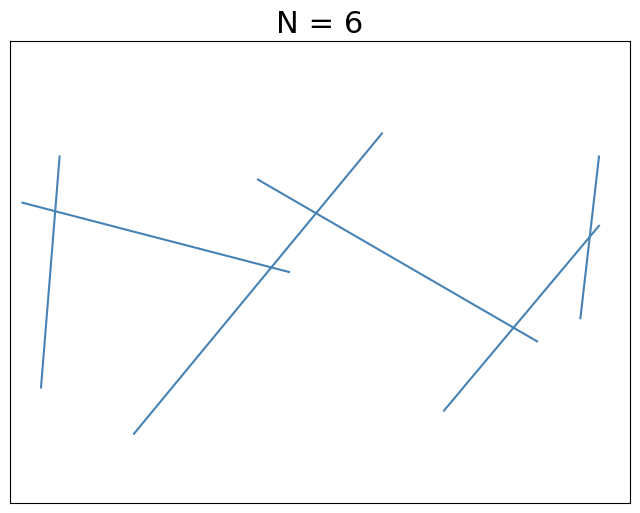

In [114]:
print("Test Case 6 - Plot 1: All line segments")
plot_lines(N_test6, points_1_test6, points_2_test6)

Test Case 6 - Plot 2: Lines with intersections


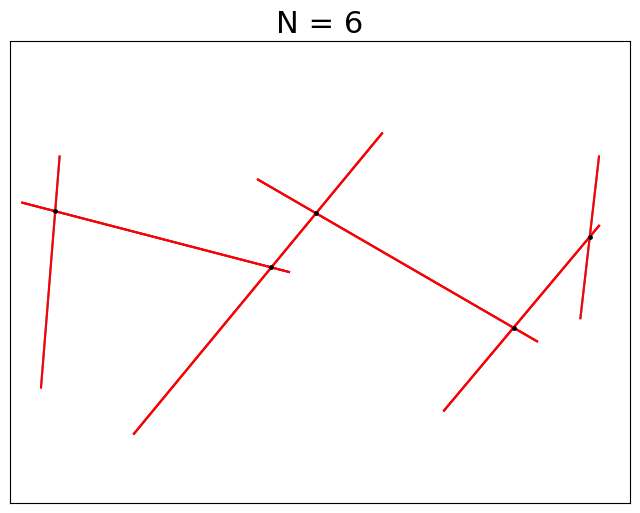

In [115]:
print("Test Case 6 - Plot 2: Lines with intersections")
plot_lines_intersection(N_test6, points_1_test6, points_2_test6,
                       intersected_line_1_test6, intersected_line_2_test6,
                       intersections_points_test6)

Test Case 6 - Plot 4: Percolating paths
1


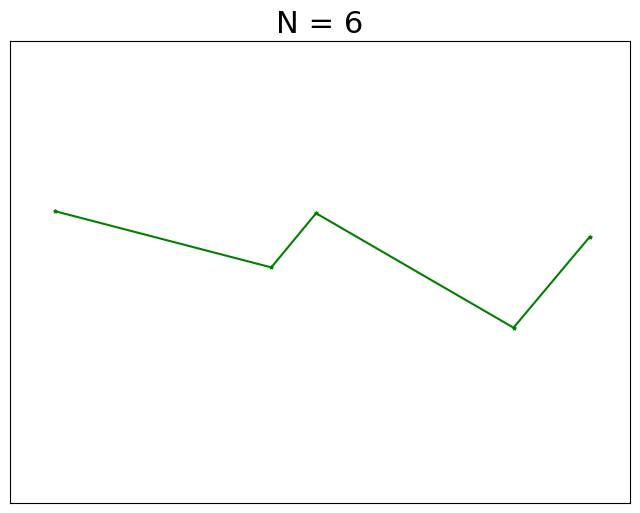

In [116]:
print("Test Case 6 - Plot 4: Percolating paths")
if len(boundary_condition_source_test6) > 0:
    # Structure data for percolating paths plot
    path_nodes_test6 = []
    path_pairs_of_edges_test6 = []
    all_path_perc_test6 = []
    
    nodes, pair_of_lines, pair_of_edges, path_perc = find_path(
        intersections_points_test6, graph_test6, boundary_condition_source_test6[0]
    )
    path_nodes_test6.append(nodes)
    path_pairs_of_edges_test6.append(pair_of_edges)
    all_path_perc_test6.append(path_perc)
    
    plot_percolating_paths(N_test6, intersections_points_test6, path_nodes_test6, 
                          path_pairs_of_edges_test6, all_path_perc_test6)
else:
    print("No paths to plot")

Test Case 6 - Plot 3: Identified paths through intersections


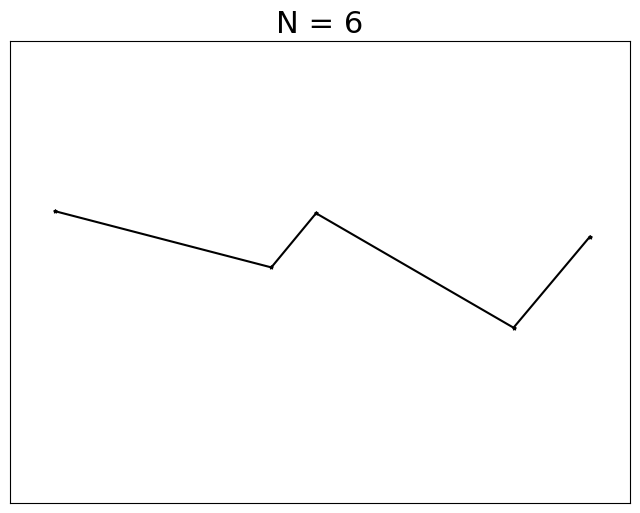

In [117]:
print("Test Case 6 - Plot 3: Identified paths through intersections")
if len(boundary_condition_source_test6) > 0:
    # Structure data for paths plot
    path_nodes_test6 = []
    path_pairs_of_edges_test6 = []
    
    nodes, pair_of_lines, pair_of_edges, path_perc = find_path(
        intersections_points_test6, graph_test6, boundary_condition_source_test6[0]
    )
    path_nodes_test6.append(nodes)
    path_pairs_of_edges_test6.append(pair_of_edges)
    
    plot_only_paths(N_test6, intersections_points_test6, path_nodes_test6, path_pairs_of_edges_test6)
else:
    print("No paths to plot")

## Test Case 7: Extended Zigzag with 31 Segments

Based on Test Case 3's design, expanded to 31 segments (21 + 10 more):
- Clean zigzag pattern with alternating upward/downward angles
- Segments well-distributed across the entire domain (x = 0.02 to 0.96)
- Each consecutive pair physically crosses at their intersection point
- Tighter spacing for comprehensive coverage (~0.03 units horizontal spacing)
- Tests scalability of the zigzag pattern with many more segments
- Ensures only real intersections between consecutive pairs

In [118]:
# Test Case 9: Extended zigzag path with 31 segments (21 + 10 more)
N_test7 = 31

# Strategy: Follow Test Case 3's successful pattern but with more segments
# Alternating steep upward and steep downward angles
# Evenly distributed across entire domain with consistent spacing
# Each consecutive pair overlaps to ensure real physical intersections
# Now with 31 segments for even better coverage

points_1_test7 = [
    [0.02, 0.25],   # 1: steep upward starting in source
    [0.05, 0.75],   # 2: steep downward from source
    [0.08, 0.20],   # 3: steep upward
    [0.11, 0.78],   # 4: steep downward
    [0.14, 0.22],   # 5: steep upward
    [0.17, 0.80],   # 6: steep downward
    [0.20, 0.20],   # 7: steep upward
    [0.23, 0.78],   # 8: steep downward
    [0.26, 0.22],   # 9: steep upward
    [0.29, 0.80],   # 10: steep downward
    [0.32, 0.20],   # 11: steep upward
    [0.35, 0.78],   # 12: steep downward
    [0.38, 0.22],   # 13: steep upward
    [0.41, 0.80],   # 14: steep downward
    [0.44, 0.20],   # 15: steep upward
    [0.47, 0.78],   # 16: steep downward
    [0.50, 0.22],   # 17: steep upward
    [0.53, 0.80],   # 18: steep downward
    [0.56, 0.20],   # 19: steep upward
    [0.59, 0.78],   # 20: steep downward
    [0.62, 0.22],   # 21: steep upward
    [0.65, 0.80],   # 22: steep downward
    [0.68, 0.20],   # 23: steep upward
    [0.71, 0.78],   # 24: steep downward
    [0.74, 0.22],   # 25: steep upward
    [0.77, 0.80],   # 26: steep downward
    [0.80, 0.20],   # 27: steep upward
    [0.83, 0.78],   # 28: steep downward
    [0.86, 0.22],   # 29: steep upward
    [0.89, 0.80],   # 30: steep downward extending toward drain
    [0.91, 0.22]    # 31: steep upward toward drain
]

points_2_test7 = [
    [0.08, 0.78],   # 1: extends into middle, overlaps segment 2
    [0.11, 0.22],   # 2: overlaps segment 3
    [0.14, 0.75],   # 3: overlaps segment 4
    [0.17, 0.25],   # 4: overlaps segment 5
    [0.20, 0.78],   # 5: overlaps segment 6
    [0.23, 0.22],   # 6: overlaps segment 7
    [0.26, 0.75],   # 7: overlaps segment 8
    [0.29, 0.25],   # 8: overlaps segment 9
    [0.32, 0.78],   # 9: overlaps segment 10
    [0.35, 0.22],   # 10: overlaps segment 11
    [0.38, 0.75],   # 11: overlaps segment 12
    [0.41, 0.25],   # 12: overlaps segment 13
    [0.44, 0.78],   # 13: overlaps segment 14
    [0.47, 0.22],   # 14: overlaps segment 15
    [0.50, 0.75],   # 15: overlaps segment 16
    [0.53, 0.25],   # 16: overlaps segment 17
    [0.56, 0.78],   # 17: overlaps segment 18
    [0.59, 0.22],   # 18: overlaps segment 19
    [0.62, 0.75],   # 19: overlaps segment 20
    [0.65, 0.25],   # 20: overlaps segment 21
    [0.68, 0.78],   # 21: overlaps segment 22
    [0.71, 0.22],   # 22: overlaps segment 23
    [0.74, 0.75],   # 23: overlaps segment 24
    [0.77, 0.25],   # 24: overlaps segment 25
    [0.80, 0.78],   # 25: overlaps segment 26
    [0.83, 0.22],   # 26: overlaps segment 27
    [0.86, 0.75],   # 27: overlaps segment 28
    [0.89, 0.25],   # 28: overlaps segment 29
    [0.92, 0.78],   # 29: overlaps segment 30
    [0.94, 0.25],   # 30: overlaps segment 31 in drain
    [0.96, 0.75]    # 31: extends well into drain region
]

print("Test Case 7: Extended zigzag path (31 segments - expanded with 10 more)")
print(f"Total segments: {N_test7}\n")
print("First 5 segments:")
for i in range(5):
    dx = points_2_test7[i][0] - points_1_test7[i][0]
    dy = points_2_test7[i][1] - points_1_test7[i][1]
    angle_deg = math.degrees(math.atan2(dy, dx))
    print(f"  Seg {i+1}: ({points_1_test7[i][0]:.3f},{points_1_test7[i][1]:.2f})→({points_2_test7[i][0]:.3f},{points_2_test7[i][1]:.2f}), ∠{angle_deg:5.1f}°")

print("\nLast 5 segments:")
for i in range(N_test7-5, N_test7):
    dx = points_2_test7[i][0] - points_1_test7[i][0]
    dy = points_2_test7[i][1] - points_1_test7[i][1]
    angle_deg = math.degrees(math.atan2(dy, dx))
    print(f"  Seg {i+1}: ({points_1_test7[i][0]:.3f},{points_1_test7[i][1]:.2f})→({points_2_test7[i][0]:.3f},{points_2_test7[i][1]:.2f}), ∠{angle_deg:5.1f}°")
# Calculate angles
angles_test7 = []
for i in range(N_test7):
    dx = points_2_test7[i][0] - points_1_test7[i][0]
    dy = points_2_test7[i][1] - points_1_test7[i][1]
    angle = math.atan2(dy, dx)
    angles_test7.append(angle)

# Identify intersections
intersections_points_test7 = []
intersected_line_1_test7 = []
intersected_line_2_test7 = []
graph_test7 = []

print("\nFinding intersections...")
intersections_points_test7, intersected_line_1_test7, intersected_line_2_test7, graph_test7 = identify_intersections(
    points_1_test7, points_2_test7,
    intersections_points_test7,
    intersected_line_1_test7, intersected_line_2_test7,
    graph_test7,
    angles_test7, 0.7, N_test7
)

print(f"\nIntersections found: {len(intersections_points_test7)}")
print(f"Expected: {N_test7 - 1} (one per consecutive pair)")
# Count intersections by region
source_count = sum(1 for pt in intersections_points_test7 if pt[0] < 0.1)
middle_count = sum(1 for pt in intersections_points_test7 if 0.1 <= pt[0] <= 0.9)
drain_count = sum(1 for pt in intersections_points_test7 if pt[0] > 0.9)
print(f"\nIntersection distribution:")
print(f"  Source region (x < 0.1): {source_count}")
print(f"  Middle region (0.1 ≤ x ≤ 0.9): {middle_count}")
print(f"  Drain region (x > 0.9): {drain_count}")

# Classify boundary nodes
boundary_condition_source_test7 = [i for i in range(len(intersections_points_test7)) if intersections_points_test7[i][0] < 0.1]
boundary_condition_drain_test7 = [i for i in range(len(intersections_points_test7)) if intersections_points_test7[i][0] > 0.9]

print(f"\nBoundary nodes:")
print(f"  Source nodes: {len(boundary_condition_source_test7)}")
print(f"  Drain nodes: {len(boundary_condition_drain_test7)}")

# Find paths
if len(boundary_condition_source_test7) > 0:
    print("\nSearching for percolating path...")
    nodes, pair_of_lines, pair_of_edges, path_perc = find_path(
        intersections_points_test7, graph_test7, boundary_condition_source_test7[0]
    )
    print(f"Path length: {len(nodes)} nodes")
    print(f"Percolates to drain: {path_perc == 1}")
    
    if path_perc == 1:
        print("\n✓ Test Case 7 PASSES - Percolation successful through 31 segments!")
    else:
        print("\n✗ Test Case 7 FAILS - Path does not reach drain")
else:
    print("\n✗ ERROR: No source nodes found")

Test Case 7: Extended zigzag path (31 segments - expanded with 10 more)
Total segments: 31

First 5 segments:
  Seg 1: (0.020,0.25)→(0.080,0.78), ∠ 83.5°
  Seg 2: (0.050,0.75)→(0.110,0.22), ∠-83.5°
  Seg 3: (0.080,0.20)→(0.140,0.75), ∠ 83.8°
  Seg 4: (0.110,0.78)→(0.170,0.25), ∠-83.5°
  Seg 5: (0.140,0.22)→(0.200,0.78), ∠ 83.9°

Last 5 segments:
  Seg 27: (0.800,0.20)→(0.860,0.75), ∠ 83.8°
  Seg 28: (0.830,0.78)→(0.890,0.25), ∠-83.5°
  Seg 29: (0.860,0.22)→(0.920,0.78), ∠ 83.9°
  Seg 30: (0.890,0.80)→(0.940,0.25), ∠-84.8°
  Seg 31: (0.910,0.22)→(0.960,0.75), ∠ 84.6°

Finding intersections...

Intersections found: 30
Expected: 30 (one per consecutive pair)

Intersection distribution:
  Source region (x < 0.1): 2
  Middle region (0.1 ≤ x ≤ 0.9): 26
  Drain region (x > 0.9): 2

Boundary nodes:
  Source nodes: 2
  Drain nodes: 2

Searching for percolating path...
Path length: 30 nodes
Percolates to drain: True

✓ Test Case 7 PASSES - Percolation successful through 31 segments!

Intersectio

### Test Case 87 Visualizations

Test Case 7 - Plot 1: All line segments


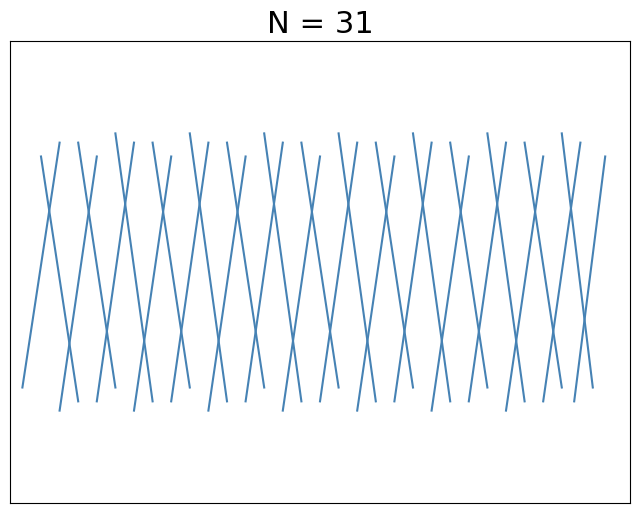

In [119]:
print("Test Case 7 - Plot 1: All line segments")
plot_lines(N_test7, points_1_test7, points_2_test7)

Test Case 7 - Plot 2: Lines with intersections


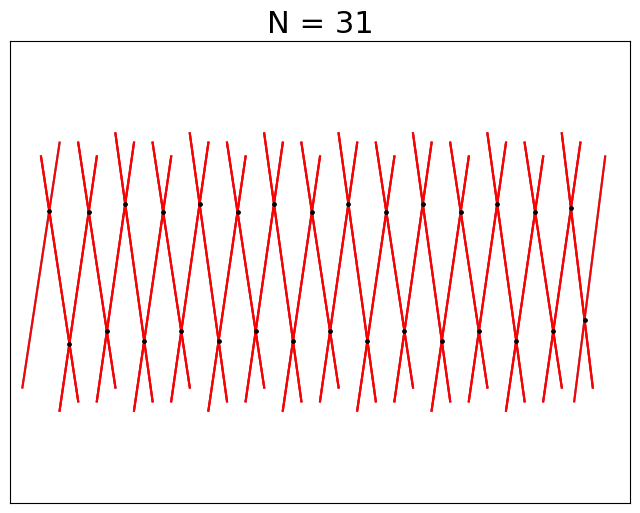

In [120]:
print("Test Case 7 - Plot 2: Lines with intersections")
plot_lines_intersection(N_test7, points_1_test7, points_2_test7,
                       intersected_line_1_test7, intersected_line_2_test7,
                       intersections_points_test7)

Test Case 7 - Plot 3: Identified paths through intersections


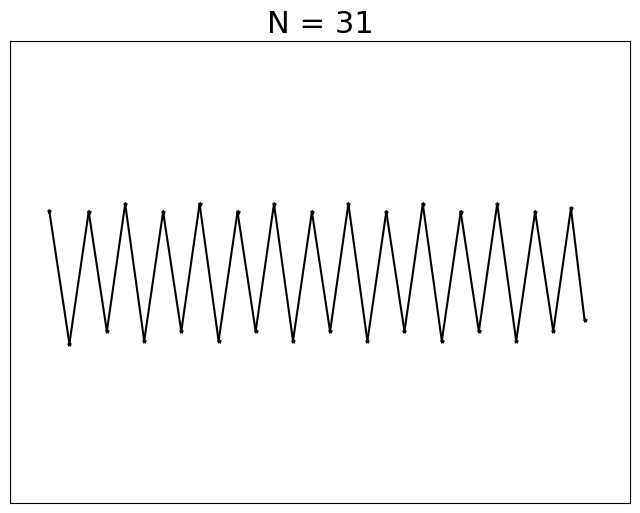

In [121]:
print("Test Case 7 - Plot 3: Identified paths through intersections")
if len(boundary_condition_source_test7) > 0:
    # Structure data for paths plot
    path_nodes_test7 = []
    path_pairs_of_edges_test7 = []

    nodes, pair_of_lines, pair_of_edges, path_perc = find_path(
        intersections_points_test7, graph_test7, boundary_condition_source_test7[0]
    )
    path_nodes_test7.append(nodes)
    path_pairs_of_edges_test7.append(pair_of_edges)

    plot_only_paths(N_test7, intersections_points_test7, path_nodes_test7, path_pairs_of_edges_test7)
else:
    print("No paths to plot")

Test Case 7 - Plot 4: Percolating paths
1


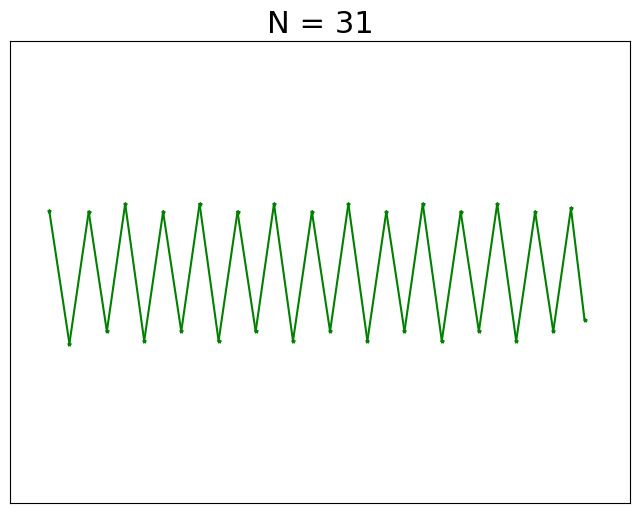

In [122]:
print("Test Case 7 - Plot 4: Percolating paths")
if len(boundary_condition_source_test7) > 0:
    # Structure data for percolating paths plot
    path_nodes_test7 = []
    path_pairs_of_edges_test7 = []
    all_path_perc_test7 = []
    nodes, pair_of_lines, pair_of_edges, path_perc = find_path(
        intersections_points_test7, graph_test7, boundary_condition_source_test7[0]
    )
    path_nodes_test7.append(nodes)
    path_pairs_of_edges_test7.append(pair_of_edges)
    all_path_perc_test7.append(path_perc)

    plot_percolating_paths(N_test7, intersections_points_test7, path_nodes_test7, 
                          path_pairs_of_edges_test7, all_path_perc_test7)
else:
    print("No paths to plot")

## Test Case 8: Non-Percolating Network (Negative Test)

A network that intentionally does NOT percolate:
- Segments in source region connect to each other
- Segments in drain region connect to each other
- Gap in the middle prevents connection between source and drain
- Tests algorithm correctly identifies non-percolating networks
- Validates that positive test results are meaningful

In [123]:
# Test Case 8: Non-percolating network (NEGATIVE TEST)
N_test8 = 5

# Strategy: Create a connected path that starts in source but STOPS in middle region
# Path has intersections in source region but never reaches drain (x > 0.9)
# This tests that algorithm correctly identifies paths that don't reach drain

points_1_test8 = [
    # Connected path from source that stops before drain
    [0.02, 0.30],   # Segment 1: starts in source, goes up-right
    [0.02, 0.65],   # Segment 2: starts in source, goes down-right
    [0.15, 0.40],   # Segment 3: middle segment going right
    [0.35, 0.30],   # Segment 4: extends path rightward
    [0.50, 0.50]    # Segment 5: final segment, but ends at x=0.70 (not drain!)
]

points_2_test8 = [
    # Endpoints create connected network in source/middle, but not reaching drain
    [0.10, 0.60],   # Segment 1: intersects in source region
    [0.20, 0.45],   # Segment 2: intersects in source/middle
    [0.40, 0.55],   # Segment 3: continues to middle
    [0.55, 0.60],   # Segment 4: extends into middle
    [0.70, 0.35]    # Segment 5: ends at x=0.70, does NOT reach drain (x>0.9)!
]

print("Test Case 8: Non-percolating network (NEGATIVE TEST)")
print("Purpose: Validate algorithm correctly identifies lack of percolation\n")
print("Network design:")
print("  • Connected path starts in source region (x < 0.1)")
print("  • Path continues through middle region")
print("  • Path STOPS at x ≈ 0.75 (does NOT reach drain region x > 0.9)")
print()

for i in range(N_test8):
    dx = points_2_test8[i][0] - points_1_test8[i][0]
    dy = points_2_test8[i][1] - points_1_test8[i][1]
    angle_deg = math.degrees(math.atan2(dy, dx))
    print(f"  Segment {i+1}: ({points_1_test8[i][0]:.2f}, {points_1_test8[i][1]:.2f}) → ({points_2_test8[i][0]:.2f}, {points_2_test8[i][1]:.2f}), angle: {angle_deg:.1f}°")

# Calculate angles
angles_test8 = []
for i in range(N_test8):
    dx = points_2_test8[i][0] - points_1_test8[i][0]
    dy = points_2_test8[i][1] - points_1_test8[i][1]
    angle = math.atan2(dy, dx)
    angles_test8.append(angle)

# Identify intersections
intersections_points_test8 = []
intersected_line_1_test8 = []
intersected_line_2_test8 = []
graph_test8 = []

intersections_points_test8, intersected_line_1_test8, intersected_line_2_test8, graph_test8 = identify_intersections(
    points_1_test8, points_2_test8,
    intersections_points_test8,
    intersected_line_1_test8, intersected_line_2_test8,
    graph_test8,
    angles_test8, 0.7, N_test8
)

print(f"\nIntersections found: {len(intersections_points_test8)}")
print("Expected: Intersections in source network and drain network, but NO connection between them")

for i, pt in enumerate(intersections_points_test8):
    region = "source" if pt[0] < 0.1 else ("drain" if pt[0] > 0.9 else "middle")
    print(f"  Node {i}: ({pt[0]:.4f}, {pt[1]:.4f}) [{region}]")

# Classify boundary nodes
boundary_condition_source_test8 = [i for i in range(len(intersections_points_test8)) if intersections_points_test8[i][0] < 0.1]
boundary_condition_drain_test8 = [i for i in range(len(intersections_points_test8)) if intersections_points_test8[i][0] > 0.9]

print(f"\nSource nodes: {boundary_condition_source_test8}")
print(f"Drain nodes: {boundary_condition_drain_test8}")

# Find paths
if len(boundary_condition_source_test8) > 0:
    print("\nSearching for percolating path from source...")
    nodes, pair_of_lines, pair_of_edges, path_perc = find_path(
        intersections_points_test8, graph_test8, boundary_condition_source_test8[0]
    )
    print(f"Path found: {nodes}")
    print(f"Path length: {len(nodes)} nodes")
    print(f"Percolates to drain: {path_perc == 1}")
    
    if path_perc == 0:
        print("\n✓ Test Case 8 PASSES - Correctly identified as NON-percolating!")
        print("  This validates that the algorithm can distinguish percolating from non-percolating networks.")
    else:
        print("\n✗ Test Case 8 FAILS - Should NOT percolate!")
        print("  ERROR: Path should be blocked by the gap!")
else:
    print("\n✗ ERROR: No source nodes found - test setup issue")

Test Case 8: Non-percolating network (NEGATIVE TEST)
Purpose: Validate algorithm correctly identifies lack of percolation

Network design:
  • Connected path starts in source region (x < 0.1)
  • Path continues through middle region
  • Path STOPS at x ≈ 0.75 (does NOT reach drain region x > 0.9)

  Segment 1: (0.02, 0.30) → (0.10, 0.60), angle: 75.1°
  Segment 2: (0.02, 0.65) → (0.20, 0.45), angle: -48.0°
  Segment 3: (0.15, 0.40) → (0.40, 0.55), angle: 31.0°
  Segment 4: (0.35, 0.30) → (0.55, 0.60), angle: 56.3°
  Segment 5: (0.50, 0.50) → (0.70, 0.35), angle: -36.9°

Intersections found: 3
Expected: Intersections in source network and drain network, but NO connection between them
  Node 0: (0.0920, 0.5700) [source]
  Node 1: (0.2117, 0.4370) [middle]
  Node 2: (0.5944, 0.6667) [middle]

Source nodes: [0]
Drain nodes: []

Searching for percolating path from source...
Path found: [0, 1, 2]
Path length: 3 nodes
Percolates to drain: False

✓ Test Case 8 PASSES - Correctly identified as 

### Test Case 8 Visualizations

Test Case 8 - Plot 1: All line segments


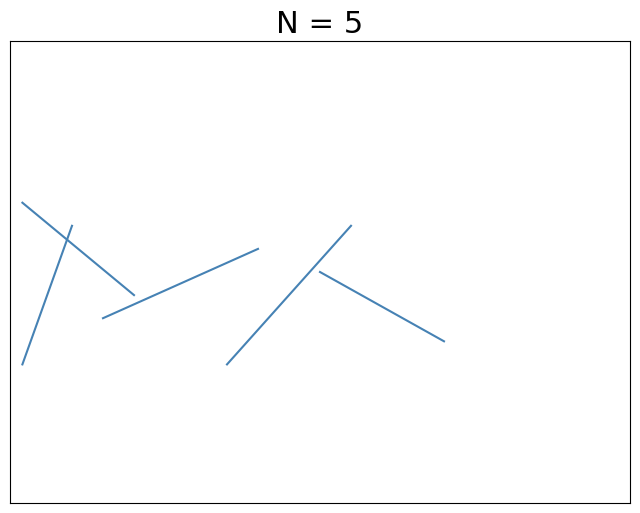

In [124]:
print("Test Case 8 - Plot 1: All line segments")
plot_lines(N_test8, points_1_test8, points_2_test8)

Test Case 8 - Plot 2: Lines with intersections


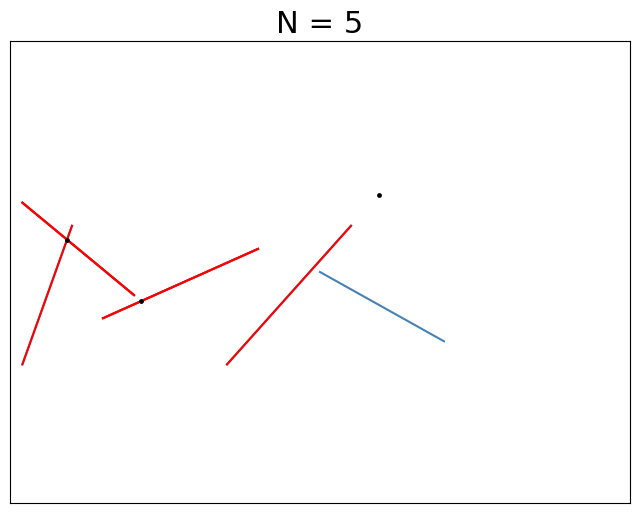

In [125]:
print("Test Case 8 - Plot 2: Lines with intersections")
plot_lines_intersection(N_test8, points_1_test8, points_2_test8,
                       intersected_line_1_test8, intersected_line_2_test8,
                       intersections_points_test8)

Test Case 8 - Plot 3: Identified paths through intersections


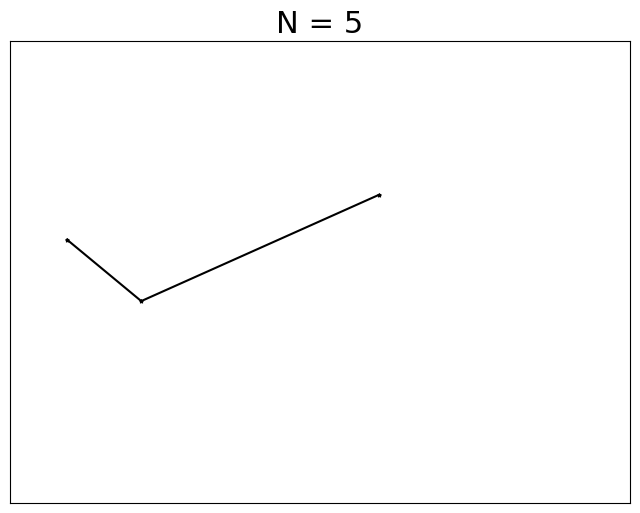

In [126]:
print("Test Case 8 - Plot 3: Identified paths through intersections")
if len(boundary_condition_source_test8) > 0:
    # Structure data for paths plot
    path_nodes_test8 = []
    path_pairs_of_edges_test8 = []
    
    nodes, pair_of_lines, pair_of_edges, path_perc = find_path(
        intersections_points_test8, graph_test8, boundary_condition_source_test8[0]
    )
    path_nodes_test8.append(nodes)
    path_pairs_of_edges_test8.append(pair_of_edges)
    
    plot_only_paths(N_test8, intersections_points_test8, path_nodes_test8, path_pairs_of_edges_test8)
else:
    print("No paths to plot")

Test Case 8 - Plot 4: Non-percolating path (should stop at gap)


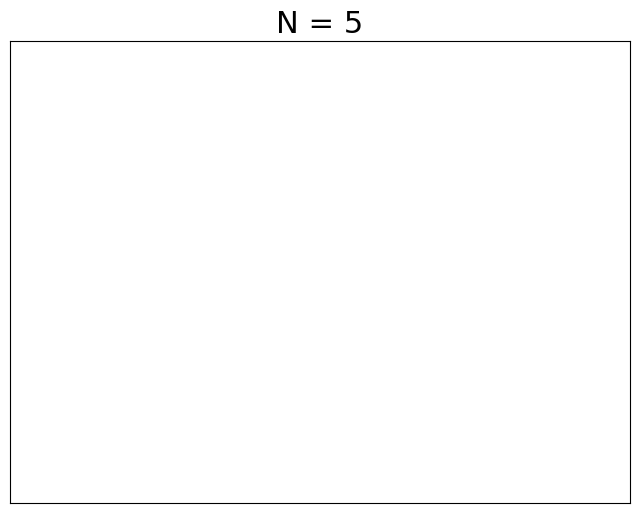


Note: Path ends at x ≈ 0.59
      Does NOT reach drain region (x > 0.9)


In [127]:
print("Test Case 8 - Plot 4: Non-percolating path (should stop at gap)")
if len(boundary_condition_source_test8) > 0:
    # Structure data for percolating paths plot
    path_nodes_test8 = []
    path_pairs_of_edges_test8 = []
    all_path_perc_test8 = []
    
    nodes, pair_of_lines, pair_of_edges, path_perc = find_path(
        intersections_points_test8, graph_test8, boundary_condition_source_test8[0]
    )
    path_nodes_test8.append(nodes)
    path_pairs_of_edges_test8.append(pair_of_edges)
    all_path_perc_test8.append(path_perc)
    
    plot_percolating_paths(N_test8, intersections_points_test8, path_nodes_test8, 
                          path_pairs_of_edges_test8, all_path_perc_test8)
    
    print(f"\nNote: Path ends at x ≈ {max(intersections_points_test8[i][0] for i in nodes):.2f}")
    print(f"      Does NOT reach drain region (x > 0.9)")
else:
    print("No paths to plot")